# Mapping the global archeomagnetic field


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`intensity`，shape `(1, 2964, 5)`，dtype `<f8`：Intensity observations; columns year CE, latitude deg, longitude deg, intensity nT, uncertainty nT.；`inclination`，shape `(1, 4253, 5)`，dtype `<f8`：Inclination observations; columns year CE, latitude deg, longitude deg, inclination deg, uncertainty deg; positive inclination points downward.；`declination`，shape `(1, 2827, 5)`，dtype `<f8`：Declination observations; columns year CE, latitude deg, longitude deg, declination deg, uncertainty deg; positive declination points east of north.。未知量为五个历元的全球N/E/D磁场图及43×15样条Gauss系数。

获取模型：球谐势梯度得到磁场，再转换为强度F、倾角I及偏角D。

如何恢复：src.solvers.reconstruct：带时空二次阻尼的Gauss–Newton；field_maps生成空间图。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell8六组scientific_review，观测残差、原始/纠正上游、场图及阻尼敏感性；非真实地磁场精度证明。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留1个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Reconstruct the evolving global magnetic vector field from irregular historical and archeomagnetic intensity and directional observations with sparse coverage across four millennia.

This review actively reconstructs the bound compilation of **10044 intensity/directional observations at1725 locations** from−2000 through1990CE. The unknown is a time-dependent global north/east/down magnetic vector field. Observations are sparse and irregular, and individual records contain intensity, inclination, or declination rather than a complete vector. These are the author's existing observation records, not a new synthetic easier problem. No independent physical truth is available.


## Current benchmark evaluation (v2, 2026-10-29)

V2 checks the observation-whitened objective plus explicitly defined integrated priors and coefficient-to-map consistency. Earlier five-step GN map/coefficients NCC/NRMSE are historical v1 reproduction diagnostics; they no longer define acceptance.

The reconstruction and scientific comparisons below retain the validated original-method path. Current Judge calls use the unchanged standalone interface and return a status/metrics report; historical comparison metrics are labeled separately.

## 2. Data

`data/raw_data.npz` contains only the supplied observations and their measurement coordinates and uncertainties. Each row consists of **year CE, geodetic latitude in degrees, east longitude in degrees, observed value, standard uncertainty**. Rows in different groups are independent observations; missing observation types have not been filled.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| `intensity` | `(1, 2964, 5)` | float64 | Intensity observations; columns year CE, latitude deg, longitude deg, intensity nT, uncertainty nT. |
| `inclination` | `(1, 4253, 5)` | float64 | Inclination observations; columns year CE, latitude deg, longitude deg, inclination deg, uncertainty deg; positive inclination points downward. |
| `declination` | `(1, 2827, 5)` | float64 | Declination observations; columns year CE, latitude deg, longitude deg, declination deg, uncertainty deg; positive declination points east of north. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Observation interval | −2000 to1990 | year CE | Bound record selection from the supplied compilation. |
| Reference radius | 6371.2 | km | Radius defining the Gauss coefficients. |
| Ellipsoid major semiaxis | 6378137 | m | Geodetic coordinate conversion. |
| Ellipsoid minor semiaxis | 6356752 | m | Rounded reference ellipsoid used by the supplied observations' model convention. |
| Observation height | 0 | m | Height above the reference ellipsoid; no height information was supplied. |
| Local vector frame | north/east/down | convention | Positive down points into Earth. |
| Longitude | east-positive, modulo360 | deg | Convert360°-wrapped longitudes consistently. |
| Coordinate conversion | flattening equals(major−minor)/major | dimensionless | Convert latitude to geocentric location and rotate local magnetic vectors. |
| Measurement error | supplied per observation | nT or deg | Use the stated uncertainty; angular residuals must account for360° periodicity. |
| Source region | internal only | convention | Neglect external and crustal fields in the long-term large-scale model. |
| Exterior boundary | decaying harmonic potential | convention | No growing external-field spherical-harmonic terms. |


## 3. Physics

### Acquisition physics and mathematical unknown

Outside the internal magnetic sources, the field is curl-free and divergence-free. Its scalar potential is


$$
V=a\sum_{n=1}^{3}\sum_{m=0}^{n}(a/r)^{n+1}[g_n^m(t)\cos(m\phi)+h_n^m(t)\sin(m\phi)]\bar P_n^m(\cos\theta),\quad \mathbf B=-\nabla V.
$$


Here a=6371.2km is the coefficient reference radius; r is geocentric radius(km); θ is colatitude; φ is east longitude; t is yearCE; Pbar are Schmidt seminormalized Legendre functions without the Condon–Shortley phase; and g,h have unitsnT. Geocentric north/east/down are X=∂θV/r, Y=−∂φV/(r sinθ), Z=∂rV. Taking the gradient yields radial powers(a/r)^(n+2). The local geodetic vector is obtained by rotating north/down by geodetic-minus-geocentric latitude.

Intensity F=sqrt(X²+Y²+Z²), inclination I=atan2(Z,sqrt(X²+Y²)), and declination D=atan2(Y,X) are the acquired scalars. Each record includes its uncertainty. The reference ellipsoid semiaxes are6378137m and6356752m; flattening equals(major−minor)/major. The original source uses exponent n+1 for B and divides flattening by minor; both disagree with the independent potential gradient/ellipsoid geometry. Corrected oracle fixtures explicitly separate these changes. All temporal and inverse-update mathematics is unchanged.


## 4. Method

### Inverse update and regularization

Each of15 degree-three Gauss coefficients is represented by43 cubic B-splines at100-year spacing, giving645 inverse coefficients. Ordinary cubic splines use47 knots from−2300 through2300CE. The objective is sum((observed−modeled)/sigma)²+cᵀPc, with direction residuals wrapped periodically. P=ζS+τT combines integrated degree-dependent Ohmic-heating and temporal-acceleration penalties. The radius ratio q=6371.2/3485 appears in spatial weights4πq^(2n+3)(n+1)(2n+1)(2n+3)/n and temporal weights4πq^(2n+4)(n+1)²/(2n+1); spatial dipole terms are exempt. Spline overlaps are integrated piecewise exactly. These spectral weights omit physical material constants and are not SI heat fluxes.

Initialize all axial dipole coefficients to−30000nT and all others tozero. At each of five iterations, construct the observable Jacobian, whiten by observation uncertainty, and solve (JᵀJ+P)δ=Jᵀr−Pc with unit step. Here r is the whitened residual and J is the whitened derivative. The standard run usesζ=1e−13,τ=1e−3. No line search, clipping, or extra fitting library replaces this update. The following cell performs the complete fresh reconstruction.
The independent Judge additionally reconstructs F/I/D at every public record from the submitted coefficients and checks each type's uncertainty-whitened RMS, using boundaries fixed to1.1 times the independently captured source values. These residual checks supplement all map/coefficients agreement checks.


The selected published method is regularized least-squares spherical-harmonic inversion with cubic temporal splines (Out etal.,2025; DOI10.1016/j.acags.2025.100222). The current source revision differs from its paper: two independently verified physical formulas need explicit corrections. We keep the unmodified upstream run, minimally corrected oracle run, and fresh local result separately identified below. The notebook uses only cleaned modules.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


In [1]:
%matplotlib inline
import os,sys,time,json,subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/raw_data.npz').exists())
if str(root) not in sys.path: sys.path.insert(0,str(root))
from src.preprocessing import load_observations
from src.physics_model import field_maps,EPOCHS
from src.solvers import reconstruct
from src.visualization import scientific_review
started=time.perf_counter()
data=load_observations()
print('Scalar observations:',len(data[0]),'counts F/I/D:',[int(np.sum(data[4]==k)) for k in [4,5,6]])

Scalar observations: 10044 counts F/I/D: [2964, 4253, 2827]


In [2]:
coefficients,diagnostics=reconstruct(data)
fresh_maps=field_maps(coefficients)
(root/'output').mkdir(exist_ok=True)
np.savez_compressed(root/'output/reconstruction.npz',reconstruction=fresh_maps[None],coefficients=coefficients[None])
reconstruction_seconds=time.perf_counter()-started
print(f'Fresh reconstruction completed in {reconstruction_seconds:.3f}s')
print('Pre-update mean absolute whitened residual:',diagnostics['weighted_mae'])
completed=subprocess.run([sys.executable,str(root/'evaluation/judge.py'),'--prediction',str(root/'output/reconstruction.npz'),'--report',str(root/'output/judge_report.json')],capture_output=True,text=True)
report=json.loads((root/'output/judge_report.json').read_text())
print('Judge:',report['status'],'metrics scored:',len(report['metrics']))
assert completed.returncode==0,report

Fresh reconstruction completed in 0.522s
Pre-update mean absolute whitened residual: [1.97331711 1.19531965 1.1513619  1.15113052 1.15109903]


Judge: pass metrics scored: 35


### Independent runs, field maps, and actual sensitivity experiments

The two archives below are independently captured upstream measurements on the exact bound observations. They are loaded only for comparison; the plotted fresh maps were computed above. The unmodified source result and minimally corrected source result are not physical truth. We show vector maps at two interior epochs, measured-versus-modeled F/I/D, axial-dipole evolution across independent runs, iteration convergence, three actively recomputed temporal-prior choices, irregular data coverage, and the change in inferred coefficients caused by the physics corrections.

The correction comparison evaluates both coefficient sets with the **correct** field law, so it isolates changed inferred coefficients; it does not silently mix two forward conventions. Map units areµT or nT as labeled. Weighted RMS and the convergence MAE are separately named and never relabeled as the same statistic.


01_global_vector_fields


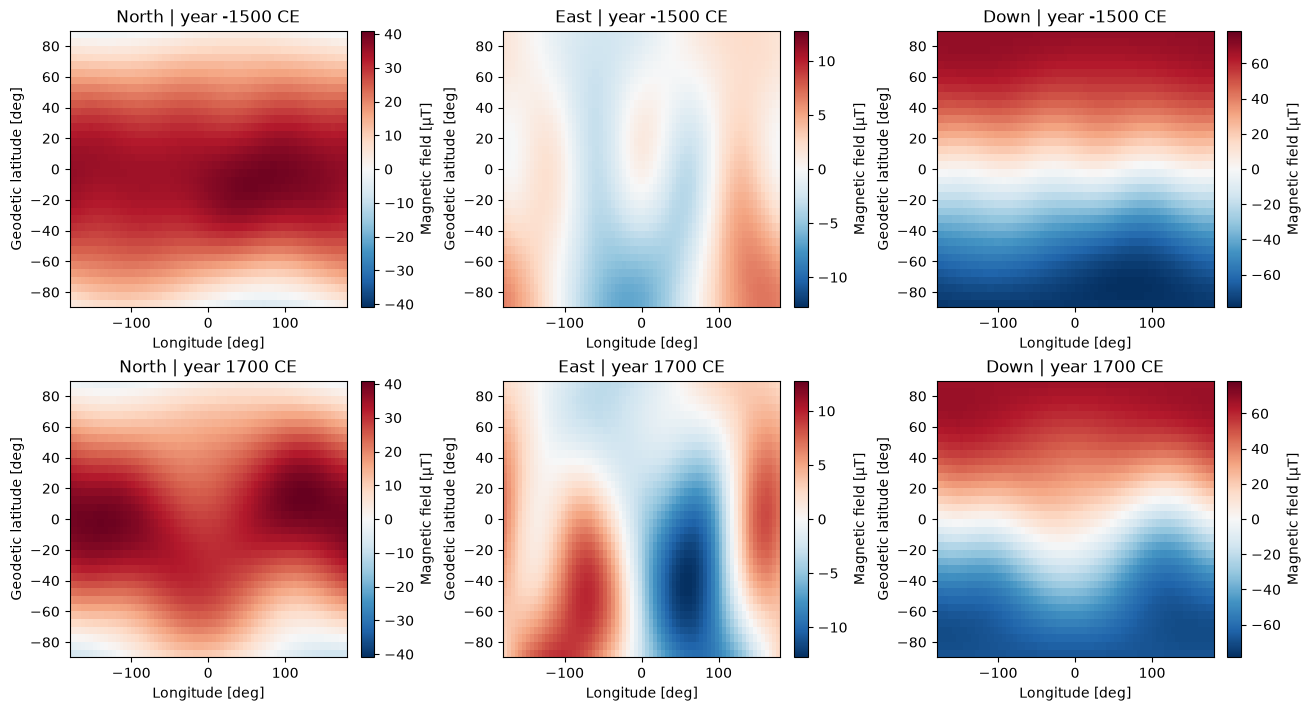

02_observation_consistency


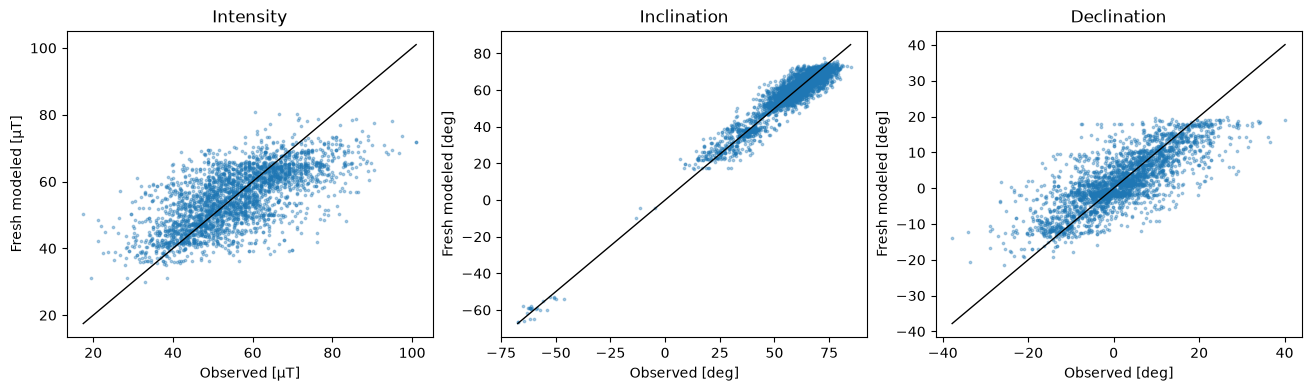

03_independent_runs_and_evolution


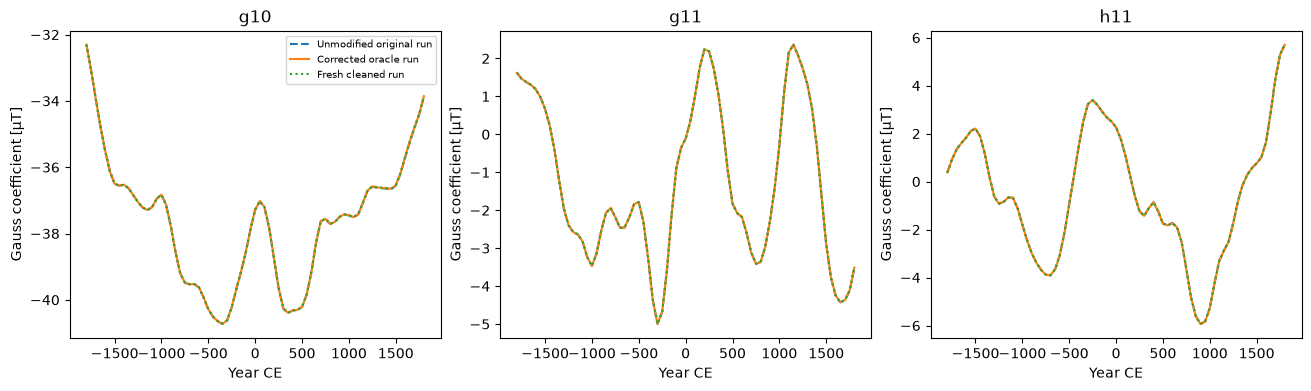

04_convergence_and_prior_sensitivity


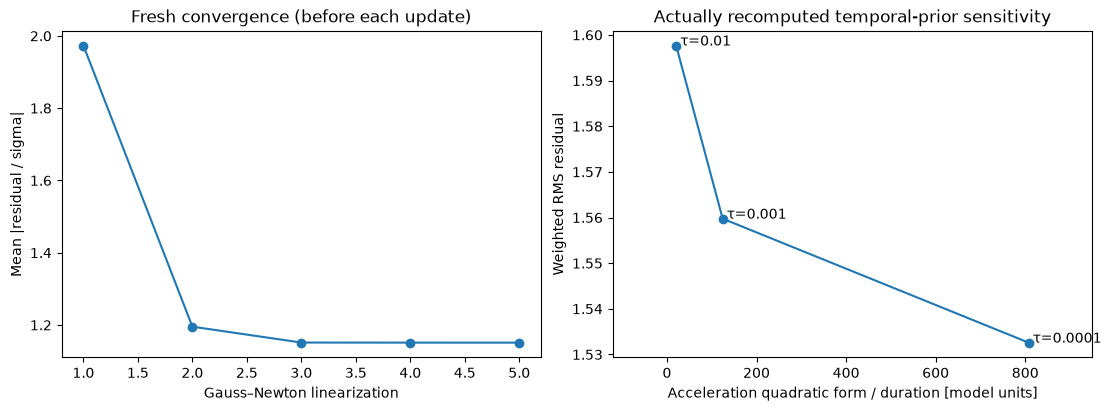

05_coverage_and_physics_corrections


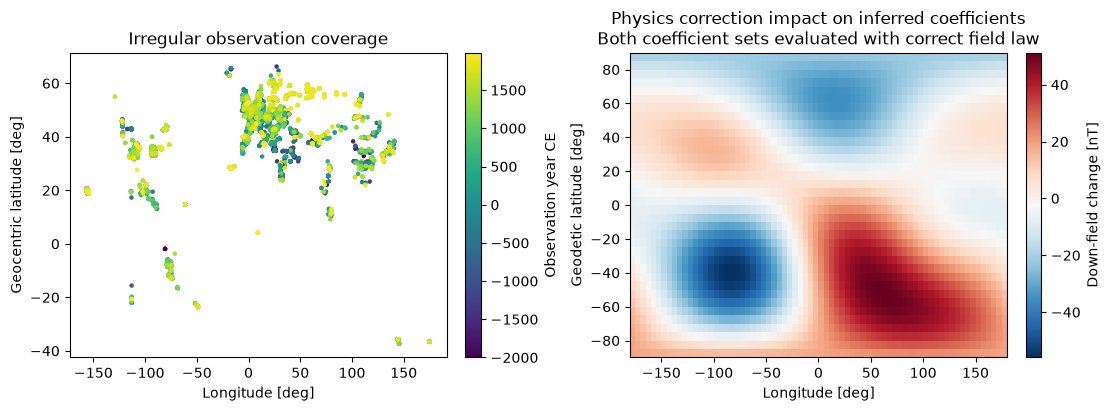

06_spatial_and_secular_variation_power


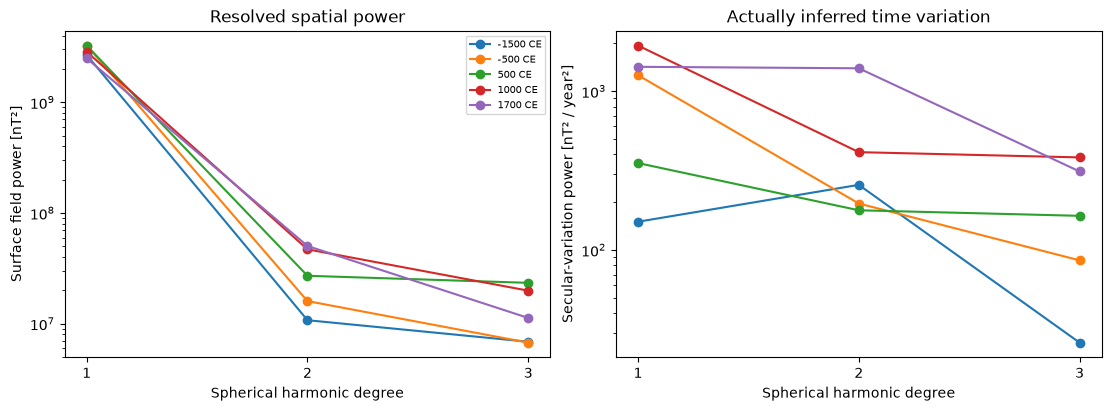

{
  "fresh_vs_corrected_coefficients": {
    "ncc": 1.0,
    "nrmse": 6.933301256713737e-17
  },
  "original_vs_corrected_coefficients": {
    "ncc": 0.999999928484457,
    "nrmse": 8.267862159629632e-05
  },
  "intensity_weighted_rms": 1.6060121973684938,
  "inclination_weighted_rms": 1.70794816253306,
  "declination_weighted_rms": 1.2452833003510602,
  "temporal_prior_sweep": [
    {
      "tau": 0.0001,
      "weighted_rms": 1.5325961251605946,
      "acceleration": 807.5665892681812
    },
    {
      "tau": 0.001,
      "weighted_rms": 1.5597504064246368,
      "acceleration": 124.4149182509336
    },
    {
      "tau": 0.01,
      "weighted_rms": 1.597679525211412,
      "acceleration": 20.53320898643698
    }
  ]
}
Complete review runtime: 15.632s


In [3]:
with np.load(root/'notebooks/reference_outputs/upstream_original.npz',allow_pickle=False) as z: original=z['coefficients'].copy()
with np.load(root/'notebooks/reference_outputs/upstream_corrected.npz',allow_pickle=False) as z: corrected=z['coefficients'].copy()
figures,numeric,measurements=scientific_review(data,coefficients,diagnostics,original,corrected,export_dir=Path('D:/yan1/agent/AutoSkill/imaging-101-maintainer/research_batch5_20261021/astro_earth/figures/archeomagnetic_global_field_mapping'))
for name,figure in figures.items():
    print(name)
    display(figure)
    plt.close(figure)
print(json.dumps(measurements,indent=2,allow_nan=False))
print(f'Complete review runtime: {time.perf_counter()-started:.3f}s')

## 6. Conclusion

### Interpretation and limitations

The fresh implementation agrees numerically with the independently corrected standard method, including every Gauss–Newton update. Observation-space residuals remain nonzero because the model truncates atdegree3 and the records contain uncertainty and uneven coverage. The regularization experiment measures the actual tradeoff between temporal roughness and observation fit.

This task deliberately retains all bound observations while reconstructing only the broad global field. Small-scale crustal/external sources, uncertain archeological ages, and model uncertainty are not estimated. A smooth result in a poorly sampled region is influenced by the prior. The maps avoid immediate temporal endpoints; even interior structure is not uniquely determined by the data. Reference agreement validates reproduction of this documented method, not proof of physical accuracy or independent validation of the underlying field.

The paper's earlier degree10/ten-year demonstration and its Fortran timing comparison are historical reports, not experiments reproduced by this task. This notebook does not replace them with invented measurements. The selected degree-three bound path, all fifteen vector maps, all645 coefficients, original-versus-corrected comparison, and three temporal-prior runs have been actively computed here.

All 645 spline coefficients describe a degree-three field; regularized maps in poorly sampled years and regions remain prior dependent. The corrected radius power and ellipsoid flattening are physical corrections, so the unmodified-source comparison is retained separately from corrected-oracle parity.
